# Defending under challenge: restate, answer, concede, what would change your mind: how do you hold a claim?

**Week 4, Tuesday, concept notebook 3 of 5, beside chapter 3 of the deck.** Gulmohar
Secondary School is invented, and so is every week of its attendance in this notebook,
written by the day's seeded generator.

**Who needs the answer.** A teacher at Gulmohar (invented) who claims at a staff meeting
that the new timetable, from week 3, raised attendance, and the headmaster, who decides
whether the timetable stays. The sports teacher objects: "Attendance rose because the exams
began." A defence that concedes nothing loses the room, and one that concedes everything
loses a term.

**The questions on the way.** Which part of the objection is true? Which evidence answers
the rest? What does the teacher's own overclaim get wrong? What does a full defence sound
like?

In [1]:
import textwrap
import pandas as pd
import matplotlib.pyplot as plt
pd.set_option("display.width", 140)
plt.rcParams.update({"figure.figsize": (9, 3.8), "font.size": 11,
                     "axes.spines.top": False, "axes.spines.right": False})
INK, VIOLET, LILAC, PALE, ROSE, AMBER = "#1A0F5C", "#5B3FD6", "#B9AEF0", "#EEEAFB", "#D63A6A", "#C98A00"

def check(name, ok):
    print(("PASS " if ok else "FAIL ") + name)

# Gulmohar's attendance, eight weeks of last year and eight of this year; every number invented
att = pd.read_csv("../data/C2_W04_D02_school_attendance_STUDENT.csv")
check("eight weeks in each year", (att.year.value_counts() == 8).all())
check("exams in weeks 6 to 8 of both years", set(att[att.exam_week == "yes"].week) == {6, 7, 8})
check("the new timetable runs from week 3, this year only",
      set(att[att.timetable_changed == "yes"].week) == set(range(3, 9))
      and set(att[att.timetable_changed == "yes"].year) == {"this year"})
print(att.to_string(index=False))

PASS eight weeks in each year
PASS exams in weeks 6 to 8 of both years
PASS the new timetable runs from week 3, this year only
     year  week  attendance_pct exam_week timetable_changed
last year     1              76        no                no
last year     2              77        no                no
last year     3              76        no                no
last year     4              77        no                no
last year     5              77        no                no
last year     6              85       yes                no
last year     7              85       yes                no
last year     8              85       yes                no
this year     1              77        no                no
this year     2              76        no                no
this year     3              81        no               yes
this year     4              82        no               yes
this year     5              81        no               yes
this year     6              89  

## Which part of the objection is true?

An **objection** is the reason a listener gives for not accepting a claim, usually built
on a number the objector can see. To **concede** is to say its true part out loud. Count by
hand first. Last year the exam weeks ran 85, 85 and 85, an average of 85.0, against 76, 77
and 77 in weeks 3 to 5, an average of 76.7. This year they ran 89, 90 and 89, an average of
89.3, against 81, 82 and 81, an average of 81.3.

**Predict before you run.** In each year, how far do the exam weeks sit above the three
weeks before them?

a) About 2 points
b) About 8 points
c) About 13 points
d) Only this year's exams lift attendance

year
last year    8.3
this year    8.0
PASS by hand and by code: 8.3 points last year and 8.0 this year


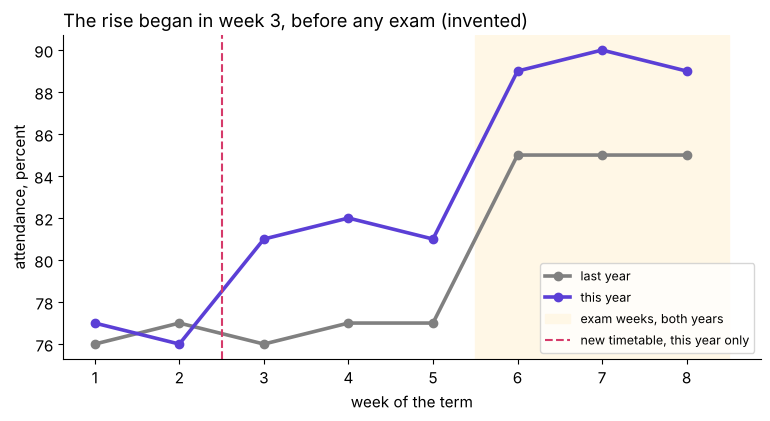

In [2]:
w = att.pivot(index="week", columns="year", values="attendance_pct")[["last year", "this year"]]
exam_lift = (w.loc[6:8].mean() - w.loc[3:5].mean()).round(1)      # each year's exams over weeks 3 to 5
print(exam_lift.rename("exam weeks over weeks 3 to 5, points").to_string())
check("by hand and by code: 8.3 points last year and 8.0 this year", list(exam_lift) == [8.3, 8.0])

fig, ax = plt.subplots(figsize=(9, 4.2))
for year, colour in (("last year", "gray"), ("this year", VIOLET)):
    ax.plot(w.index, w[year], color=colour, lw=2.6, marker="o", label=year)
ax.axvspan(5.5, 8.5, color="#FFF7E6", label="exam weeks, both years")
ax.axvline(2.5, color=ROSE, ls="--", label="new timetable, this year only")
ax.set_xlabel("week of the term")
ax.set_ylabel("attendance, percent")
ax.set_title("The rise began in week 3, before any exam (invented)", loc="left")
ax.legend(loc="lower right", fontsize=9)
plt.show()

**What happened.** The answer is b: 8.3 points last year and 8.0 this year. That is the true
part of the objection, and it holds in both years: exam weeks run about 8 points above the
weeks before them with or without the new timetable. The picture shows where the objection
stops being true: the two lines agree in weeks 1 and 2 and part from week 3, before any
exam.

## Which evidence answers the rest?

Compare like with like: the same weeks of the term, this year against last year, so the
exams and the season cancel out.

**Predict before you run.** How far do weeks 3 to 5 this year sit above the same weeks last
year?

a) About the same
b) About 4.7 points higher
c) About 12.8 points higher
d) Lower

weeks 3 to 5: 81.3 this year against 76.7 last year, 4.7 points apart
weeks 1 and 2: 76.5 in both years
PASS weeks 1 and 2 match across the years
PASS weeks 3 to 5 sit 4.7 points above last year's


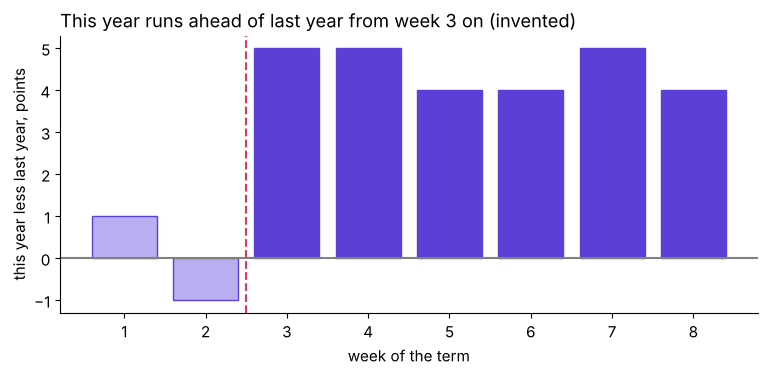

In [3]:
early = w.loc[3:5].mean()
rise = round(early["this year"] - early["last year"], 1)            # the timetable's weeks, before any exam
start = w.loc[1:2].mean()
gap = w["this year"] - w["last year"]                               # this year less last year, week by week
print(f"weeks 3 to 5: {early['this year']:.1f} this year against {early['last year']:.1f} last year, {rise} points apart")
print(f"weeks 1 and 2: {start['this year']:.1f} in both years")
check("weeks 1 and 2 match across the years", start["this year"] == start["last year"] == 76.5)
check("weeks 3 to 5 sit 4.7 points above last year's", rise == 4.7)

fig, ax = plt.subplots(figsize=(9, 3.6))
ax.bar(gap.index, gap, color=[LILAC if wk < 3 else VIOLET for wk in gap.index], edgecolor=VIOLET)
ax.axhline(0, color="gray")
ax.axvline(2.5, color=ROSE, ls="--")
ax.set_xlabel("week of the term")
ax.set_ylabel("this year less last year, points")
ax.set_title("This year runs ahead of last year from week 3 on (invented)", loc="left")
plt.show()

**What happened.** The answer is b. Weeks 3 to 5 this year average 81.3 against last year's
76.7, 4.7 points apart, before any exam; weeks 1 and 2 sit at 76.5 in both years. The
concession carries one number, about 8 points of exam lift in both years, and the answer
carries another, 4.7 points before the exams.

## What does the teacher's own overclaim get wrong?

**The plausible wrong answer.** "Attendance rose 12.8 points this term, from 76.5 to 89.3,
so the timetable did it, and the exams are irrelevant." It concedes nothing, and every
number in it is right.

**Predict before you run.** Last year, with the old timetable, how far did the exam weeks
rise above weeks 3 to 5?

a) Not at all
b) About 4 points
c) About 8 points
d) The full 12.8 points

the overclaim credits the timetable with 12.8 points
last year, with the old timetable, the exam weeks still rose 8.3 points
PASS the overclaim is 12.8 points
PASS most of it is the exams' lift, which last year shows without the timetable


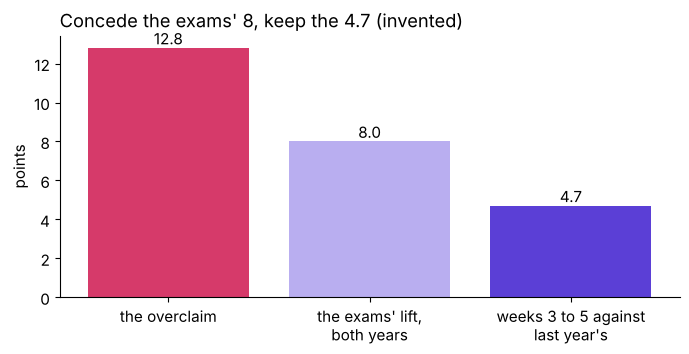

In [4]:
overclaim = round(w.loc[6:8, "this year"].mean() - start["this year"], 1)
print(f"the overclaim credits the timetable with {overclaim} points")
print(f"last year, with the old timetable, the exam weeks still rose {exam_lift['last year']} points")
check("the overclaim is 12.8 points", overclaim == 12.8)
check("most of it is the exams' lift, which last year shows without the timetable", exam_lift["last year"] > overclaim / 2)

fig, ax = plt.subplots(figsize=(8, 3.4))
labels = ["the overclaim", "the exams' lift,\nboth years", "weeks 3 to 5 against\nlast year's"]
bars = ax.bar(labels, [overclaim, exam_lift["this year"], rise], color=[ROSE, LILAC, VIOLET])
ax.bar_label(bars, fmt="%.1f")
ax.set_ylabel("points")
ax.set_title("Concede the exams' 8, keep the 4.7 (invented)", loc="left")
plt.show()

**Why it is wrong.** The answer is c, 8.3 points: the 12.8 points run from the first weeks to
the exam weeks, so they carry the exams' lift, which last year shows without any new
timetable. The sports teacher
is partly right, and a reply that denies it hands the staff room to her. **The check:** did
the reply name the true part and the line of evidence, in that order? **The fix:** concede
the exams' 8 points and claim only what the like-for-like weeks show, 4.7.

## What does a full defence sound like?

The four moves, named last, run in this order. **Restate** the objection until its owner agrees with
your version. **Answer** from a named line of the evidence. **Concede** the true part out
loud. Say **what would change your mind**, so the claim can be tested. Restating comes
first because the objector has to accept your version before any answer lands; Rapoport's
rules, the philosopher Daniel Dennett's guide to criticising an argument fairly (as The
Marginalian quotes his Intuition Pumps, checked 13 October 2026), open the same way. The cell
writes the four moves from the two numbers the cells computed.

In [5]:
moves = {                                       # defending under challenge: the four moves, in order
    "restate": "You are saying attendance rose because the exams began, so the timetable may have done nothing.",
    "answer": f"Weeks 3 to 5 this year sit {rise} points above the same weeks last year, before any exam.",
    "concede": f"You are right that exam weeks run about {exam_lift.mean():.0f} points higher; they did in both years.",
    "change my mind": ("If a school with the same exams and the old timetable showed the same rise in weeks 3 to 5, "
                       "I would drop the claim.")}
for move, words in moves.items():
    print(f"{move:>15}: {words}")
check("the answer names the line of evidence, 4.7 points", str(rise) in moves["answer"])
check("the concession names the true part, the exams", "exam" in moves["concede"])

        restate: You are saying attendance rose because the exams began, so the timetable may have done nothing.
         answer: Weeks 3 to 5 this year sit 4.7 points above the same weeks last year, before any exam.
        concede: You are right that exam weeks run about 8 points higher; they did in both years.
 change my mind: If a school with the same exams and the old timetable showed the same rise in weeks 3 to 5, I would drop the claim.
PASS the answer names the line of evidence, 4.7 points
PASS the concession names the true part, the exams


**Your turn.** The headmaster pushes once more: "The rise is a three-week blip; it will
fade." Find the evidence in the exam weeks: compare this year's exam weeks with last year's,
then check that the gap holds about the size it had before the exams. Fill the blank, type
the lines into the empty cell below and run them, then write the four moves for the new
objection the same way, as a new `moves`:

```python
exam_gap = w.loc[6:8, "this year"].mean() - w.loc[6:8, "last year"].___()
print(round(exam_gap, 1))
check("the gap holds through the exam weeks", abs(exam_gap - rise) < 1)
```

## Which rules does the chapter leave?

1. Restate the objection until its owner agrees with your version.
2. Answer from a named line of the evidence, never from the claim repeated.
3. Concede the true part out loud; the claim survives it.
4. Say the fact that would change your mind, so the claim can be tested.

These are the four moves of defending under challenge: restate, answer, concede, what would
change your mind. A defence fails two ways: overclaiming concedes nothing, and retreating
concedes everything.

**In the interview.** [F] A stakeholder's objection is partly right; how do you answer it?

**Where it is used next.** Chapter 5's notebook,
`C2_W04_D02_05_case_defending_under_challenge_evidence_STUDENT.ipynb`, finds the true part
of each of Uber's three objections in the case's own tables and answers the rest with a
line of evidence.